# Startup de Logística: Baja California
Resolución de misiones operativas y estratégicas mediante algoritmos de clusterización.

## Fase 1: Exploración Inicial

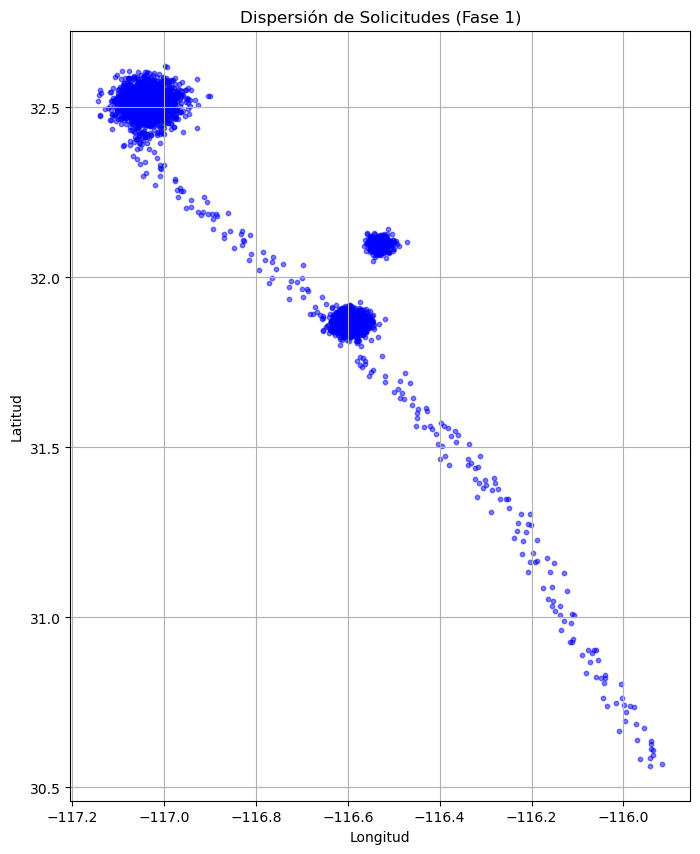

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


csv_path = os.path.join("data", "logistica_baja_california.csv")
df = pd.read_csv(csv_path)

# Caracteristicas necesarias en (X)
X = df[['Longitud', 'Latitud']]

# Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Datos Crudos
plt.figure(figsize=(8, 10))
plt.scatter(df['Longitud'], df['Latitud'], alpha=0.5, s=10, c='blue')
plt.title('Dispersión de Solicitudes (Fase 1)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid(True)
plt.show()

## Fase 2: Misión Estratégica (Ubicación de 3 Cedis)

Coordenadas de los Cedis (K-Means):
Cedi 1: Latitud 32.5063, Longitud -117.0350
Cedi 2: Latitud 31.0405, Longitud -116.1380
Cedi 3: Latitud 31.9123, Longitud -116.5807


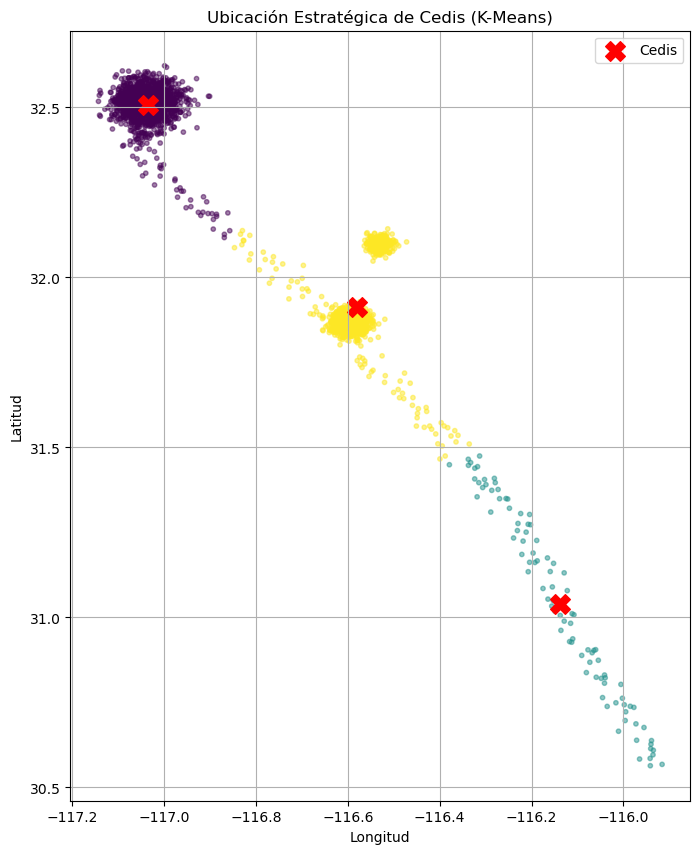

In [4]:
from sklearn.cluster import KMeans

# Utilizamos KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

centros_scaled = kmeans.cluster_centers_
centros_reales = scaler.inverse_transform(centros_scaled)

print("Coordenadas de los Cedis (K-Means):")
for i, c in enumerate(centros_reales):
    print(f"Cedi {i+1}: Latitud {c[1]:.4f}, Longitud {c[0]:.4f}")

plt.figure(figsize=(8, 10))
plt.scatter(df['Longitud'], df['Latitud'], c=kmeans_labels, cmap='viridis', alpha=0.5, s=10)
plt.scatter(centros_reales[:, 0], centros_reales[:, 1], c='red', marker='X', s=200, label='Cedis')
plt.title('Ubicación Estratégica de Cedis (K-Means)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(True)
plt.show()

### Análisis de Fase 2
**1. ¿Qué algoritmo se adecua más a este problema?**
K-Means, dado que su función matemática (minimizar la suma de distancias al cuadrado hacia el centroide) cumple exactamente con el objetivo de negocio de "encontrar el centro geográfico de la demanda" minimizando tiempos de viaje totales.
K-Menas, dado que buscamos encontrar el centro geografico de la demanda, donde se busca poner los centros dentro de los lugares que tienen mayor demanda.

**2. ¿Dónde colocó el algoritmo las Cedis? ¿Hacen sentido?**
- **Tijuana:** (Lat: ~32.50, Lon: -117.03) -> SI
- **Ensenada:** (Lat: ~31.91, Lon: -116.58) -> SI
- **Zona Rural al Sur (Punta Colonet / San Vicente):** (Lat: ~31.04, Lon: -116.13) -> No mucho, ya que se encuentra en un outlier

**3. ¿Por qué la matemática de este algoritmo provocó esto?**
Porque K-Means es altamente sensible a los valores atípicos (outliers) y solo toma en cuenta distancias euclidianas para minimizar la varianza, sin entender el concepto de *densidad poblacional*. Un pequeño grupo de viajes lejanos hacia el sur arrastra todo el centroide hacia abajo a un punto despoblado, simplemente para "equilibrar" la ecuación de distancias.
Porque k-means es sensible a los outliers, y cuando ve un outlier que puede ser muy chico se concentra en él para mantener las distancias relativas.

## Fase 3: Misión Operativa (Manchas Urbanas y Zonas Calientes)

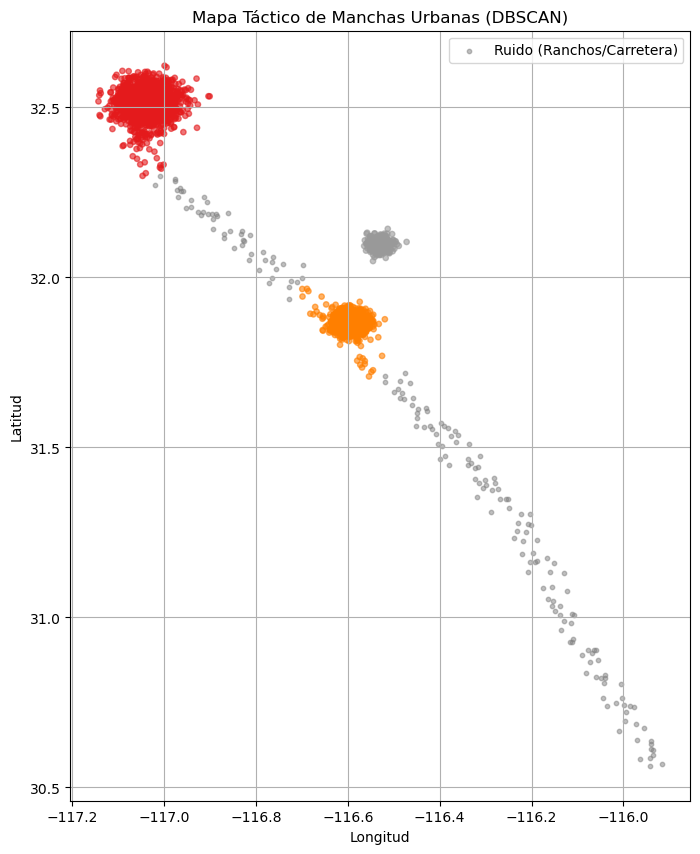

In [8]:
from sklearn.cluster import DBSCAN
import numpy as np

# Utilizamos DBSCAN porque nos permite aislar el 'ruido' (puntos aislados en carreteras)
# y agrupar únicamente las zonas con alta densidad (manchas urbanas).
dbscan = DBSCAN(eps=0.2, min_samples=30)
db_labels = dbscan.fit_predict(X_scaled)

df['Cluster_DBSCAN'] = db_labels

plt.figure(figsize=(8, 10))
# Dibujar el ruido en gris oscuro
ruido = df[df['Cluster_DBSCAN'] == -1]
plt.scatter(ruido['Longitud'], ruido['Latitud'], c='gray', alpha=0.5, s=10, label='Ruido (Ranchos/Carretera)')

# Dibujar las manchas urbanas
manchas = df[df['Cluster_DBSCAN'] != -1]
plt.scatter(manchas['Longitud'], manchas['Latitud'], c=manchas['Cluster_DBSCAN'], cmap='Set1', alpha=0.6, s=15)

plt.title('Mapa Táctico de Manchas Urbanas (DBSCAN)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(True)
plt.show()

### Análisis de Fase 3
**1. ¿Usaron el mismo algoritmo que en la misión anterior?**
No. En lugar de K-Means, utilizamos **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise).

**2. De no ser así, ¿por qué se comportaron diferentes?**
Se comportan de forma distinta debido a su base matemática. Mientras KMeans asume agrupaciones esféricas minimizando distancias globales, DBSCAN se basa en la **densidad** local. DBSCAN requiere que existan por lo menos $N$ puntos (min_samples) agrupados estrechamente (eps). Al no cumplirse esta densidad en las carreteras y poblados alejados, DBSCAN descarta matemáticamente estos puntos como ruido (Cluster -1), enfocándose únicamente en manchas urbanas consolidadas.

**3. ¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?**
1. **Tijuana** (y zona conurbada).
2. **Ensenada**.
3. **Valle de Guadalupe** (coordenadas aproximadas 32.09 N, -116.53 O, una importante zona turística y logística en el estado).